# Importing Required Libraries

In [165]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

# Stats
from scipy import stats
from scipy.stats import ttest_rel

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

# Business Problem

The company wants to understand and process the data coming out of data engineering pipelines:

1. Clean, sanitize and manipulate data to get useful features out of raw fields.

2. Make sense out of the raw data and help the data science team to build forecasting models on it.

**Short Summary:** In short, the project focuses on transforming raw delivery data into meaningful operational insights that can help Delhivery improve speed, accuracy, and logistics planning.

## Importing the Dataset

In [178]:
!gdown 1LDr5XLNQfpfP96MrMOyPcxjsxFTz4qWM

Downloading...
From: https://drive.google.com/uc?id=1LDr5XLNQfpfP96MrMOyPcxjsxFTz4qWM
To: /content/delhivery_data.csv
100% 55.6M/55.6M [00:00<00:00, 187MB/s]


In [179]:
df = pd.read_csv("delhivery_data.csv")

## Basic Data Exploration

In [168]:
df.head()

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
0,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:27:55,10.435660,14.0,11.0,11.9653,1.272727,14.0,11.0,11.9653,1.272727
1,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:17:55,18.936842,24.0,20.0,21.7243,1.200000,10.0,9.0,9.7590,1.111111
2,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:01:19.505586,27.637279,40.0,28.0,32.5395,1.428571,16.0,7.0,10.8152,2.285714
3,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 03:39:57,36.118028,62.0,40.0,45.5620,1.550000,21.0,12.0,13.0224,1.750000
4,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 03:33:55,39.386040,68.0,44.0,54.2181,1.545455,6.0,5.0,3.9153,1.200000


In [169]:
# Shape of the dataset -

print("No. of rows: {}".format(df.shape[0]))
print("No. of cols: {}".format(df.shape[1]))

No. of rows: 144867
No. of cols: 24


In [170]:
# Checking the data type -

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144867 entries, 0 to 144866
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   data                            144867 non-null  object 
 1   trip_creation_time              144867 non-null  object 
 2   route_schedule_uuid             144867 non-null  object 
 3   route_type                      144867 non-null  object 
 4   trip_uuid                       144867 non-null  object 
 5   source_center                   144867 non-null  object 
 6   source_name                     144574 non-null  object 
 7   destination_center              144867 non-null  object 
 8   destination_name                144606 non-null  object 
 9   od_start_time                   144867 non-null  object 
 10  od_end_time                     144867 non-null  object 
 11  start_scan_to_end_scan          144867 non-null  float64
 12  is_cutoff       

In [171]:
df.describe(include = 'all')

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
count,144867,144867,144867,144867,144867,144867,144574,144867,144606,144867,...,144867,144867.000000,144867.000000,144867.000000,144867.000000,144867.000000,144867.000000,144867.000000,144867.00000,144867.000000
unique,2,14817,1504,2,14817,1508,1498,1481,1468,26369,...,93180,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,training,2018-09-22 04:55:04.835022,thanos::sroute:4029a8a2-6c74-4b7e-a6d8-f9e069f...,FTL,trip-153759210483476123,IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),2018-09-21 18:37:09.322207,...,2018-09-24 05:19:20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,104858,101,1812,99660,101,23347,23347,15192,15192,81,...,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,234.073372,416.927527,213.868272,284.771297,2.120107,36.196111,18.507548,22.82902,2.218368
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,344.990009,598.103621,308.011085,421.119294,1.715421,53.571158,14.775960,17.86066,4.847530
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,9.000045,9.000000,6.000000,9.008200,0.144000,-244.000000,0.000000,0.00000,-23.444444
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,23.355874,51.000000,27.000000,29.914700,1.604264,20.000000,11.000000,12.07010,1.347826
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,66.126571,132.000000,64.000000,78.525800,1.857143,29.000000,17.000000,23.51300,1.684211
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,286.708875,513.000000,257.000000,343.193250,2.213483,40.000000,22.000000,27.81325,2.250000


## Data Cleaning

In [180]:
# Checking for duplicate rows

print("No. of duplicate rows: ", df.duplicated().sum())

No. of duplicate rows:  0


### Converting datetime columns

In [181]:
datetime_cols = ["trip_creation_time", "od_start_time", "od_end_time"]
for col in datetime_cols:
  if col in df.columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

### Converting cutoff_timestamp column

In [182]:
df["cutoff_timestamp"] = df["cutoff_timestamp"].astype(str).str.strip()

# Parse mixed-format date strings
df["cutoff_timestamp_clean"] = pd.to_datetime(
    df["cutoff_timestamp"], format="mixed", errors="coerce"
)

# Handle any remaining numeric Excel serial dates
mask = (
    df["cutoff_timestamp_clean"].isna()
    & pd.to_numeric(df["cutoff_timestamp"], errors="coerce").notna()
)
if mask.sum() > 0:
    df.loc[mask, "cutoff_timestamp_clean"] = pd.to_datetime(
        pd.to_numeric(df.loc[mask, "cutoff_timestamp"]),
        unit="D",
        origin="1899-12-30"
    )

# Drop original raw column
df.drop("cutoff_timestamp", axis=1, inplace=True)

**Note:** This column has 2 different formats in the csv file. Hence for cleaning and standardizing the cutoff_timestamp column I have first parsed the mixed-format date strings into proper datetimes, and then converted the remaining numeric excel serial dates into valid timestamps.

Once the data is cleaned I have dropped the initial cutoff_timestamp column.

### Converting categorical columns

In [183]:
cat_cols = [
    'data',
    'route_type',
    'source_center',
    'source_name',
    'destination_center',
    'destination_name'
]
for col in cat_cols:
  if col in df.columns:
    df[col] = df[col].astype("category")

In [184]:
# After conversion data types of all columns

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144867 entries, 0 to 144866
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   data                            144867 non-null  category      
 1   trip_creation_time              144867 non-null  datetime64[ns]
 2   route_schedule_uuid             144867 non-null  object        
 3   route_type                      144867 non-null  category      
 4   trip_uuid                       144867 non-null  object        
 5   source_center                   144867 non-null  category      
 6   source_name                     144574 non-null  category      
 7   destination_center              144867 non-null  category      
 8   destination_name                144606 non-null  category      
 9   od_start_time                   144867 non-null  datetime64[ns]
 10  od_end_time                     144867 non-null  datetim

### Handling Missing Values

In [185]:
# Checking for null values -

df.isnull().sum() / len(df) * 100

,0
data,0.000000
trip_creation_time,0.000000
route_schedule_uuid,0.000000
route_type,0.000000
trip_uuid,0.000000
source_center,0.000000
source_name,0.202254
destination_center,0.000000
destination_name,0.180165
od_start_time,0.000000


In [186]:
# Filling the missing source/destination names with 'Unknown'

str_fill_cols = ["source_name", "destination_name"]
for col in str_fill_cols:
    if col in df.columns:
        # Convert to string category first, add 'Unknown' category
        df[col] = df[col].cat.add_categories("Unknown")
        df[col] = df[col].fillna("Unknown")

In [187]:
# After handling the missing values, re-checking the missing value count

df.isnull().sum() / len(df) * 100

,0
data,0.0
trip_creation_time,0.0
route_schedule_uuid,0.0
route_type,0.0
trip_uuid,0.0
source_center,0.0
source_name,0.0
destination_center,0.0
destination_name,0.0
od_start_time,0.0


## Univariate Analysis

### Distribution of numeric columns

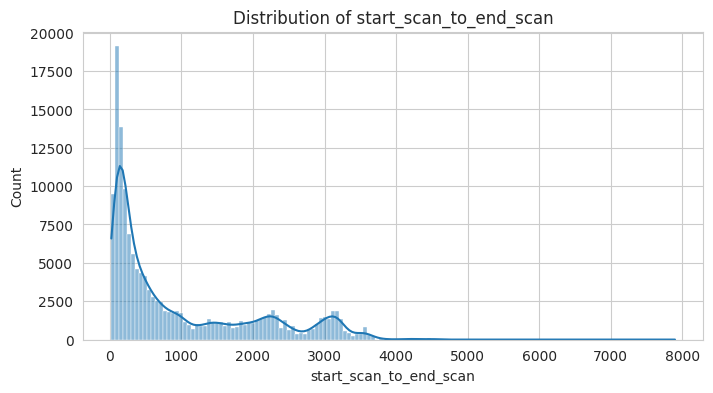

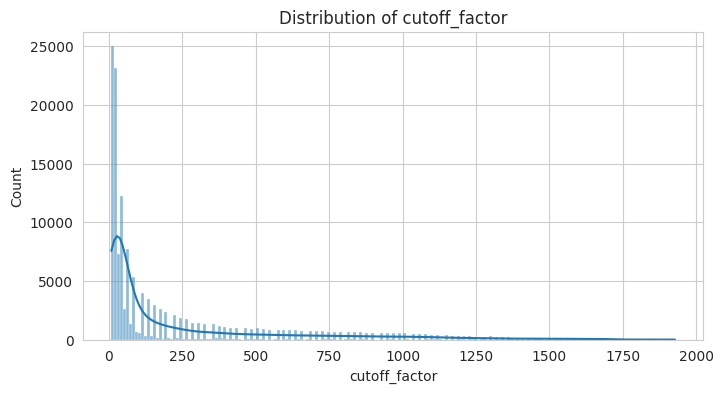

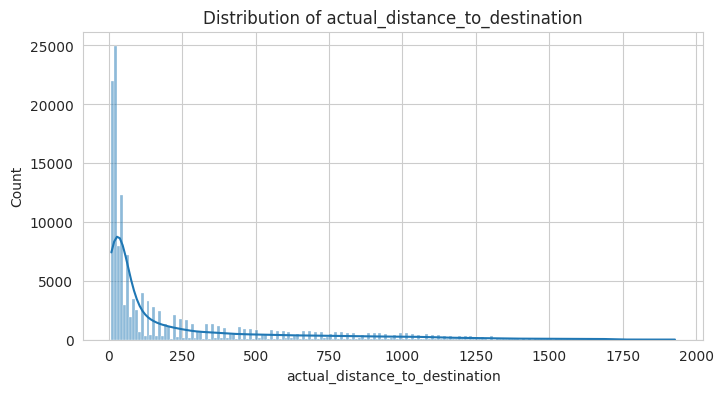

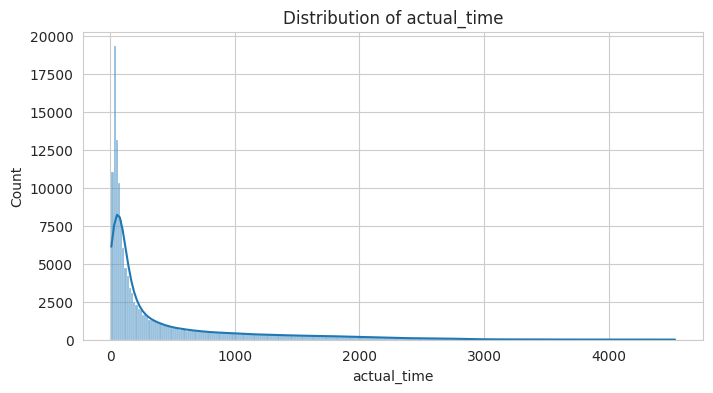

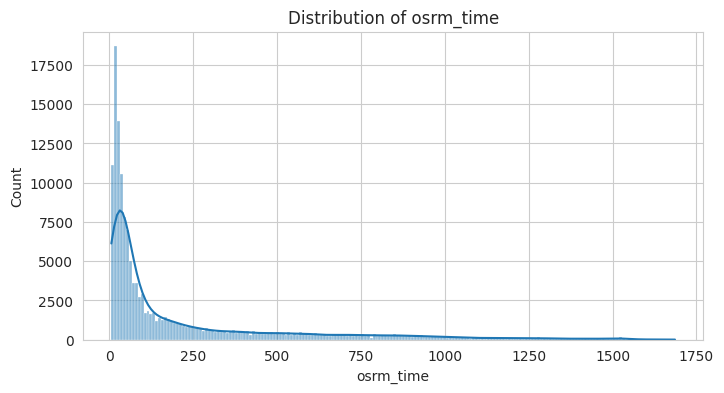

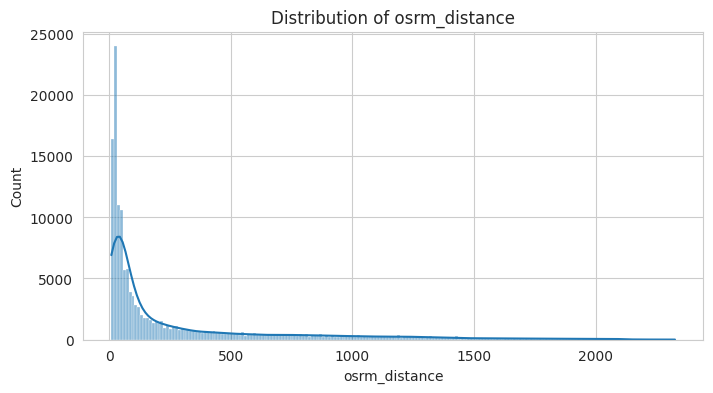

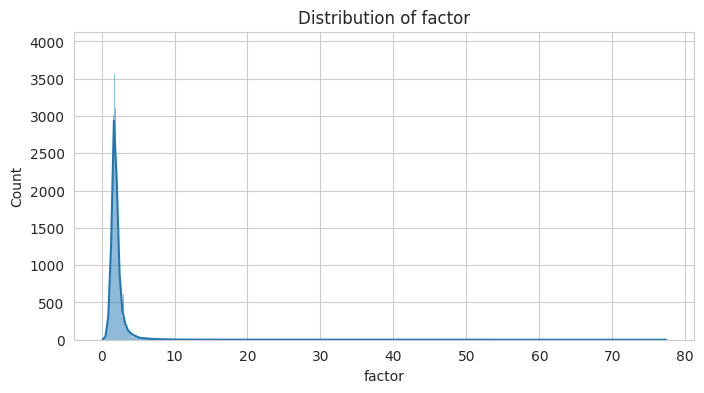

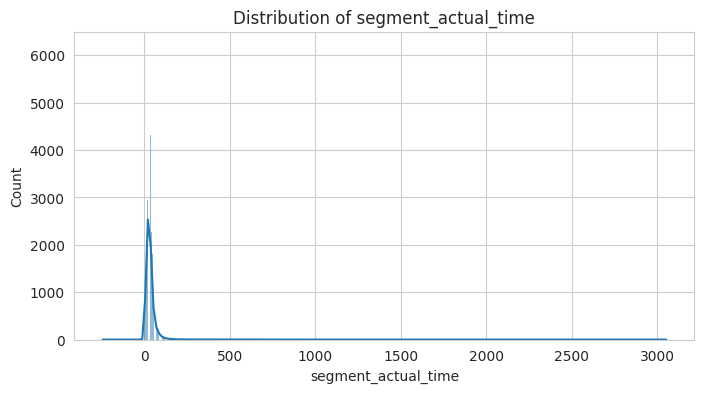

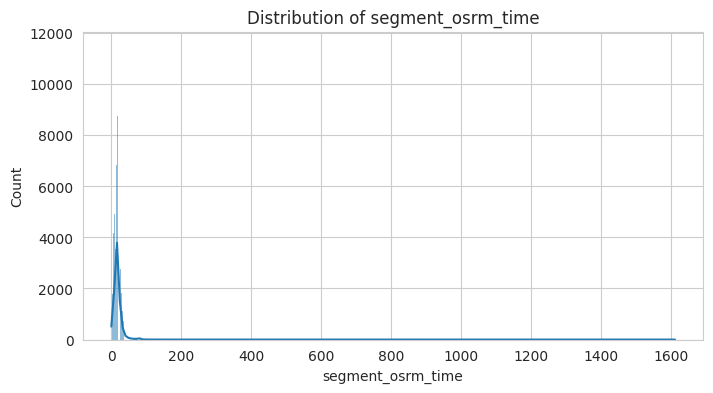

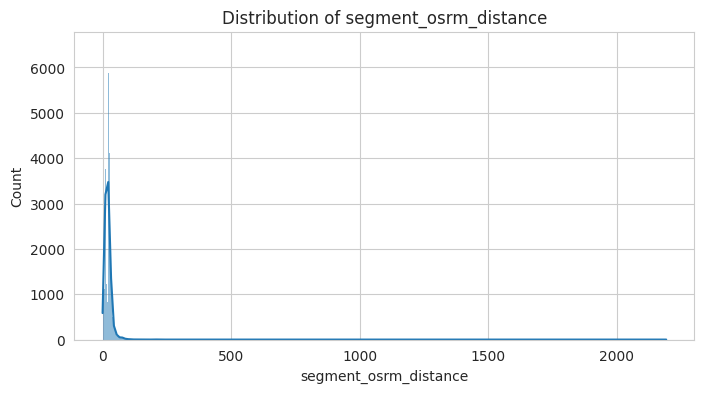

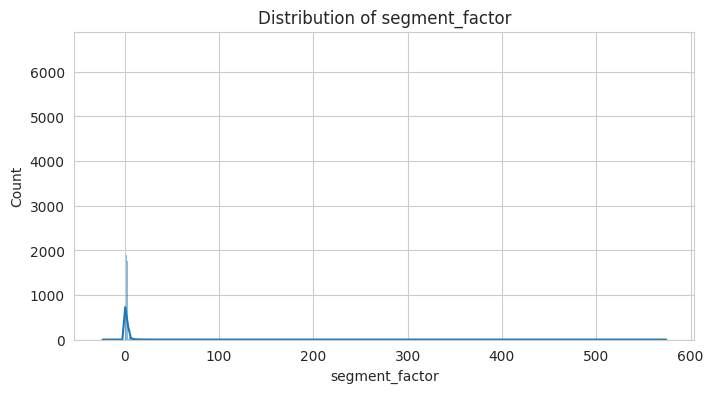

In [188]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    plt.figure(figsize=(8,4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

**Observations:**
1. Most numerical variables are positively skewed.
2. Delivery times and distances contain extreme values.
3. OSRM values are generally lower than actual values.

### Distribution of categorical columns

data
training    104858
test         40009
Name: count, dtype: int64


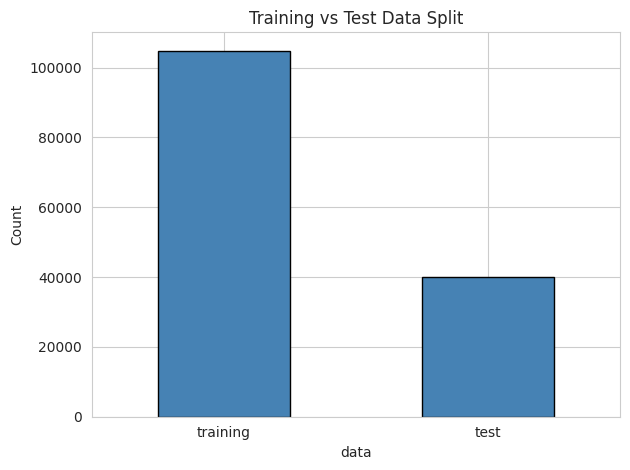


Route Type value counts:
route_type
FTL        99660
Carting    45207
Name: count, dtype: int64


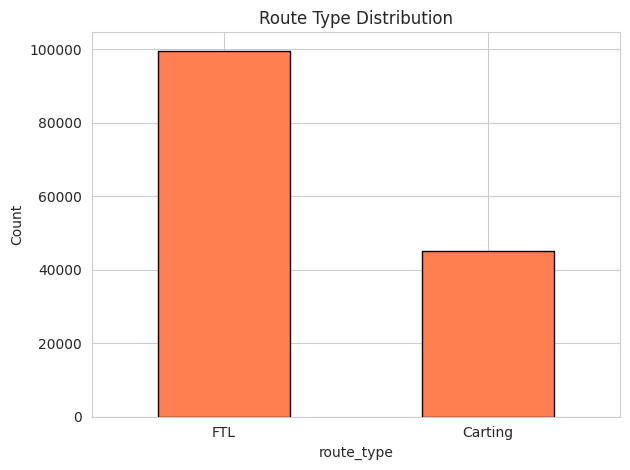

In [191]:
print(df["data"].value_counts())

df["data"].value_counts().plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Training vs Test Data Split")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nRoute Type value counts:")
print(df["route_type"].value_counts())

df["route_type"].value_counts().plot(kind="bar", color="coral", edgecolor="black")
plt.title("Route Type Distribution")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Dataset Characteristics

In [121]:
# Unique trips
print("Unique Trips:", df['trip_uuid'].nunique())

# Unique source centers
print("Unique Source Centers:", df['source_center'].nunique())

# Unique destination centers
print("Unique Destination Centers:", df['destination_center'].nunique())

# Route type distribution
print(df['route_type'].value_counts())

Unique Trips: 14817
Unique Source Centers: 1508
Unique Destination Centers: 1481
route_type
FTL        99660
Carting    45207
Name: count, dtype: int64


## Creating Segment Key

In [192]:
df["segment_key"] = (
    df["trip_uuid"].astype(str)
    + "_"
    + df["source_center"].astype(str)
    + "_"
    + df["destination_center"].astype(str)
)

print("\nSample segment keys:")
print(df[["trip_uuid", "segment_key"]].head())



Sample segment keys:
                 trip_uuid                                        segment_key
0  trip-153741093647649320  trip-153741093647649320_IND388121AAA_IND388620AAB
1  trip-153741093647649320  trip-153741093647649320_IND388121AAA_IND388620AAB
2  trip-153741093647649320  trip-153741093647649320_IND388121AAA_IND388620AAB
3  trip-153741093647649320  trip-153741093647649320_IND388121AAA_IND388620AAB
4  trip-153741093647649320  trip-153741093647649320_IND388121AAA_IND388620AAB


### Sorting chronologically within each segment

In [193]:
df = df.sort_values(by=["segment_key", "od_end_time"]).reset_index(drop=True)

### Computing cumulative sums for segment-level sub-metrics

In [194]:
df["segment_actual_time_sum"] = (
    df.groupby("segment_key")["segment_actual_time"].transform("sum")
)
df["segment_osrm_distance_sum"] = (
    df.groupby("segment_key")["segment_osrm_distance"].transform("sum")
)
df["segment_osrm_time_sum"] = (
    df.groupby("segment_key")["segment_osrm_time"].transform("sum")
)

print("\nSegment sum columns created:")
print(
    df[
        ["segment_actual_time_sum", "segment_osrm_distance_sum", "segment_osrm_time_sum"]
    ].head())


Segment sum columns created:
   segment_actual_time_sum  segment_osrm_distance_sum  segment_osrm_time_sum
0                    728.0                   670.6205                  534.0
1                    728.0                   670.6205                  534.0
2                    728.0                   670.6205                  534.0
3                    728.0                   670.6205                  534.0
4                    728.0                   670.6205                  534.0


### Defining segment-level aggregation dictionary

In [195]:
create_segment_dict = {
    "trip_uuid": "first",
    "data": "first",
    "route_schedule_uuid": "first",
    "route_type": "first",
    "source_center": "first",
    "source_name": "first",
    "destination_center": "last",
    "destination_name": "last",
    "od_start_time": "first",
    "od_end_time": "last",
    "start_scan_to_end_scan": "sum",
    "actual_distance_to_destination": "last",
    "actual_time": "last",
    "osrm_time": "last",
    "osrm_distance": "last",
    "segment_actual_time_sum": "last",
    "segment_osrm_distance_sum": "last",
    "segment_osrm_time_sum": "last",
    "factor": "first",
    "segment_factor": "first",
    "cutoff_factor": "first",
    "is_cutoff": "last",
    "cutoff_timestamp_clean": "last",
}

### Aggregate to one row per segment

In [197]:
segment = df.groupby("segment_key").agg(create_segment_dict).reset_index()

# Sort by segment_key then od_end_time ascending
segment = segment.sort_values(
    by=["segment_key", "od_end_time"], ascending=[True, True]
).reset_index(drop=True)

print(f"\nOriginal rows      : {len(df)}")
print(f"Segment-level rows : {len(segment)}")
print(f"Unique segments    : {segment['segment_key'].nunique()}")
print("\nSegment sample:")
print(segment.head())


Original rows      : 144867
Segment-level rows : 26368
Unique segments    : 26368

Segment sample:
                                         segment_key                trip_uuid  \
0  trip-153671041653548748_IND209304AAA_IND000000ACB  trip-153671041653548748   
1  trip-153671041653548748_IND462022AAA_IND209304AAA  trip-153671041653548748   
2  trip-153671042288605164_IND561203AAB_IND562101AAA  trip-153671042288605164   
3  trip-153671042288605164_IND572101AAA_IND561203AAB  trip-153671042288605164   
4  trip-153671043369099517_IND000000ACB_IND160002AAC  trip-153671043369099517   

       data                                route_schedule_uuid route_type  \
0  training  thanos::sroute:d7c989ba-a29b-4a0b-b2f4-288cdc6...        FTL   
1  training  thanos::sroute:d7c989ba-a29b-4a0b-b2f4-288cdc6...        FTL   
2  training  thanos::sroute:3a1b0ab2-bb0b-4c53-8c59-eb2a2c0...    Carting   
3  training  thanos::sroute:3a1b0ab2-bb0b-4c53-8c59-eb2a2c0...    Carting   
4  training  thanos::sroute:

## Feature Engineering

### OD Time Difference (hours)

In [199]:
segment["od_time_diff_hour"] = (
    segment["od_end_time"] - segment["od_start_time"]
).dt.total_seconds() / 3600

# Clip negative values
segment["od_time_diff_hour"] = segment["od_time_diff_hour"].clip(lower=0)

print("od_time_diff_hour created.")
print(segment["od_time_diff_hour"].describe())

od_time_diff_hour created.
count    26368.000000
mean         4.980538
std          7.344894
min          0.345047
25%          1.517248
50%          2.541975
75%          5.118318
max        131.642533
Name: od_time_diff_hour, dtype: float64


### Extract features from Source Name

In [200]:
segment["source_state"] = (
    segment["source_name"].astype(str).str.extract(r"\((.*?)\)")
)
segment["source_city"] = (
    segment["source_name"].astype(str).str.split("_").str[0]
)
segment["source_place"] = (
    segment["source_name"].astype(str).str.split("_").str[1]
)

# Fill NaN values that may arise from 'Unknown' rows
segment["source_state"].fillna("Unknown", inplace=True)
segment["source_city"].fillna("Unknown", inplace=True)
segment["source_place"].fillna("Unknown", inplace=True)

print("\nSource name features extracted:")
print(segment[["source_name", "source_city", "source_place", "source_state"]].head(5))


Source name features extracted:
                          source_name source_city source_place    source_state
0  Kanpur_Central_H_6 (Uttar Pradesh)      Kanpur      Central   Uttar Pradesh
1  Bhopal_Trnsport_H (Madhya Pradesh)      Bhopal     Trnsport  Madhya Pradesh
2   Doddablpur_ChikaDPP_D (Karnataka)  Doddablpur     ChikaDPP       Karnataka
3       Tumkur_Veersagr_I (Karnataka)      Tumkur     Veersagr       Karnataka
4       Gurgaon_Bilaspur_HB (Haryana)     Gurgaon     Bilaspur         Haryana


### Extract features from Destination Name

In [201]:
segment["destination_state"] = (
    segment["destination_name"].astype(str).str.extract(r"\((.*?)\)")
)
segment["destination_city"] = (
    segment["destination_name"].astype(str).str.split("_").str[0]
)
segment["destination_place"] = (
    segment["destination_name"].astype(str).str.split("_").str[1]
)

segment["destination_state"].fillna("Unknown", inplace=True)
segment["destination_city"].fillna("Unknown", inplace=True)
segment["destination_place"].fillna("Unknown", inplace=True)

print("\nDestination name features extracted:")
print(
    segment[
        ["destination_name", "destination_city", "destination_place", "destination_state"]
    ].head(5))


Destination name features extracted:
                     destination_name destination_city destination_place  \
0       Gurgaon_Bilaspur_HB (Haryana)          Gurgaon          Bilaspur   
1  Kanpur_Central_H_6 (Uttar Pradesh)           Kanpur           Central   
2   Chikblapur_ShntiSgr_D (Karnataka)       Chikblapur          ShntiSgr   
3   Doddablpur_ChikaDPP_D (Karnataka)       Doddablpur          ChikaDPP   
4      Chandigarh_Mehmdpur_H (Punjab)       Chandigarh          Mehmdpur   

  destination_state  
0           Haryana  
1     Uttar Pradesh  
2         Karnataka  
3         Karnataka  
4            Punjab  


### Extract temporal features from trip_creation_time

In [202]:
segment["trip_year"]      = segment["od_start_time"].dt.year
segment["trip_month"]     = segment["od_start_time"].dt.month
segment["trip_day"]       = segment["od_start_time"].dt.day
segment["trip_hour"]      = segment["od_start_time"].dt.hour
segment["trip_dayofweek"] = segment["od_start_time"].dt.dayofweek  # Mon=0, Sun=6
segment["is_weekend"]     = segment["trip_dayofweek"].isin([5, 6]).astype(int)

print("\nTemporal features extracted:")
print(
    segment[["trip_year", "trip_month", "trip_day", "trip_hour", "trip_dayofweek", "is_weekend"]].head()
)


Temporal features extracted:
   trip_year  trip_month  trip_day  trip_hour  trip_dayofweek  is_weekend
0       2018           9        12         16               2           0
1       2018           9        12          0               2           0
2       2018           9        12          2               2           0
3       2018           9        12          0               2           0
4       2018           9        14          3               4           0


### Creating Corridor feature (State-level)

In [203]:
segment["corridor"] = segment["source_state"] + " -> " + segment["destination_state"]
print("\nSample corridors:")
print(segment["corridor"].value_counts().head(10))


Sample corridors:
corridor
Maharashtra -> Maharashtra          3255
Karnataka -> Karnataka              3158
Tamil Nadu -> Tamil Nadu            2021
Uttar Pradesh -> Uttar Pradesh      1526
Telangana -> Telangana              1315
West Bengal -> West Bengal          1296
Gujarat -> Gujarat                  1279
Andhra Pradesh -> Andhra Pradesh    1139
Rajasthan -> Rajasthan              1054
Bihar -> Bihar                      1011
Name: count, dtype: int64


## Trip_Level Aggregation

### Sorting segments within each trip by od_end_time before aggregating

In [204]:
segment = segment.sort_values(by=["trip_uuid", "od_end_time"]).reset_index(drop=True)

In [205]:
create_trip_dict = {
    "route_type": "first",
    "data": "first",
    "source_center": "first",
    "source_name": "first",
    "source_city": "first",
    "source_state": "first",
    "destination_center": "last",
    "destination_name": "last",
    "destination_city": "last",
    "destination_state": "last",
    "corridor": "last",
    "actual_time": "last",
    "osrm_time": "last",
    "osrm_distance": "last",
    "segment_actual_time_sum": "sum",
    "segment_osrm_distance_sum": "sum",
    "segment_osrm_time_sum": "sum",
    "od_time_diff_hour": "sum",
    "actual_distance_to_destination": "last",
    "start_scan_to_end_scan": "sum",
    "trip_month": "first",
    "trip_day": "first",
    "trip_hour": "first",
    "trip_dayofweek": "first",
    "is_weekend": "first",
}

In [207]:
trip = segment.groupby("trip_uuid").agg(create_trip_dict).reset_index()

print(f"Trip-level shape: {trip.shape}")
print("\nTrip sample:")
print(trip.head())
print("\nTrip describe:")
print(trip.describe())

Trip-level shape: (14817, 26)

Trip sample:
                 trip_uuid route_type      data source_center  \
0  trip-153671041653548748        FTL  training  IND462022AAA   
1  trip-153671042288605164    Carting  training  IND572101AAA   
2  trip-153671043369099517        FTL  training  IND562132AAA   
3  trip-153671046011330457    Carting  training  IND400072AAB   
4  trip-153671052974046625        FTL  training  IND583101AAA   

                          source_name               source_city  \
0  Bhopal_Trnsport_H (Madhya Pradesh)                    Bhopal   
1       Tumkur_Veersagr_I (Karnataka)                    Tumkur   
2    Bangalore_Nelmngla_H (Karnataka)                 Bangalore   
3            Mumbai Hub (Maharashtra)  Mumbai Hub (Maharashtra)   
4              Bellary_Dc (Karnataka)                   Bellary   

     source_state destination_center                   destination_name  \
0  Madhya Pradesh       IND000000ACB      Gurgaon_Bilaspur_HB (Haryana)   
1       Karn

## Outlier Detetction and Treatment

In [208]:
outlier_cols = [
    "actual_time",
    "osrm_time",
    "osrm_distance",
    "segment_actual_time_sum",
    "segment_osrm_distance_sum",
    "segment_osrm_time_sum",
    "od_time_diff_hour",
    "actual_distance_to_destination",
    "start_scan_to_end_scan",
]
outlier_cols = [c for c in outlier_cols if c in trip.columns]

# Ensure numeric
trip[outlier_cols] = trip[outlier_cols].apply(pd.to_numeric, errors="coerce")

### Boxplots before treatment

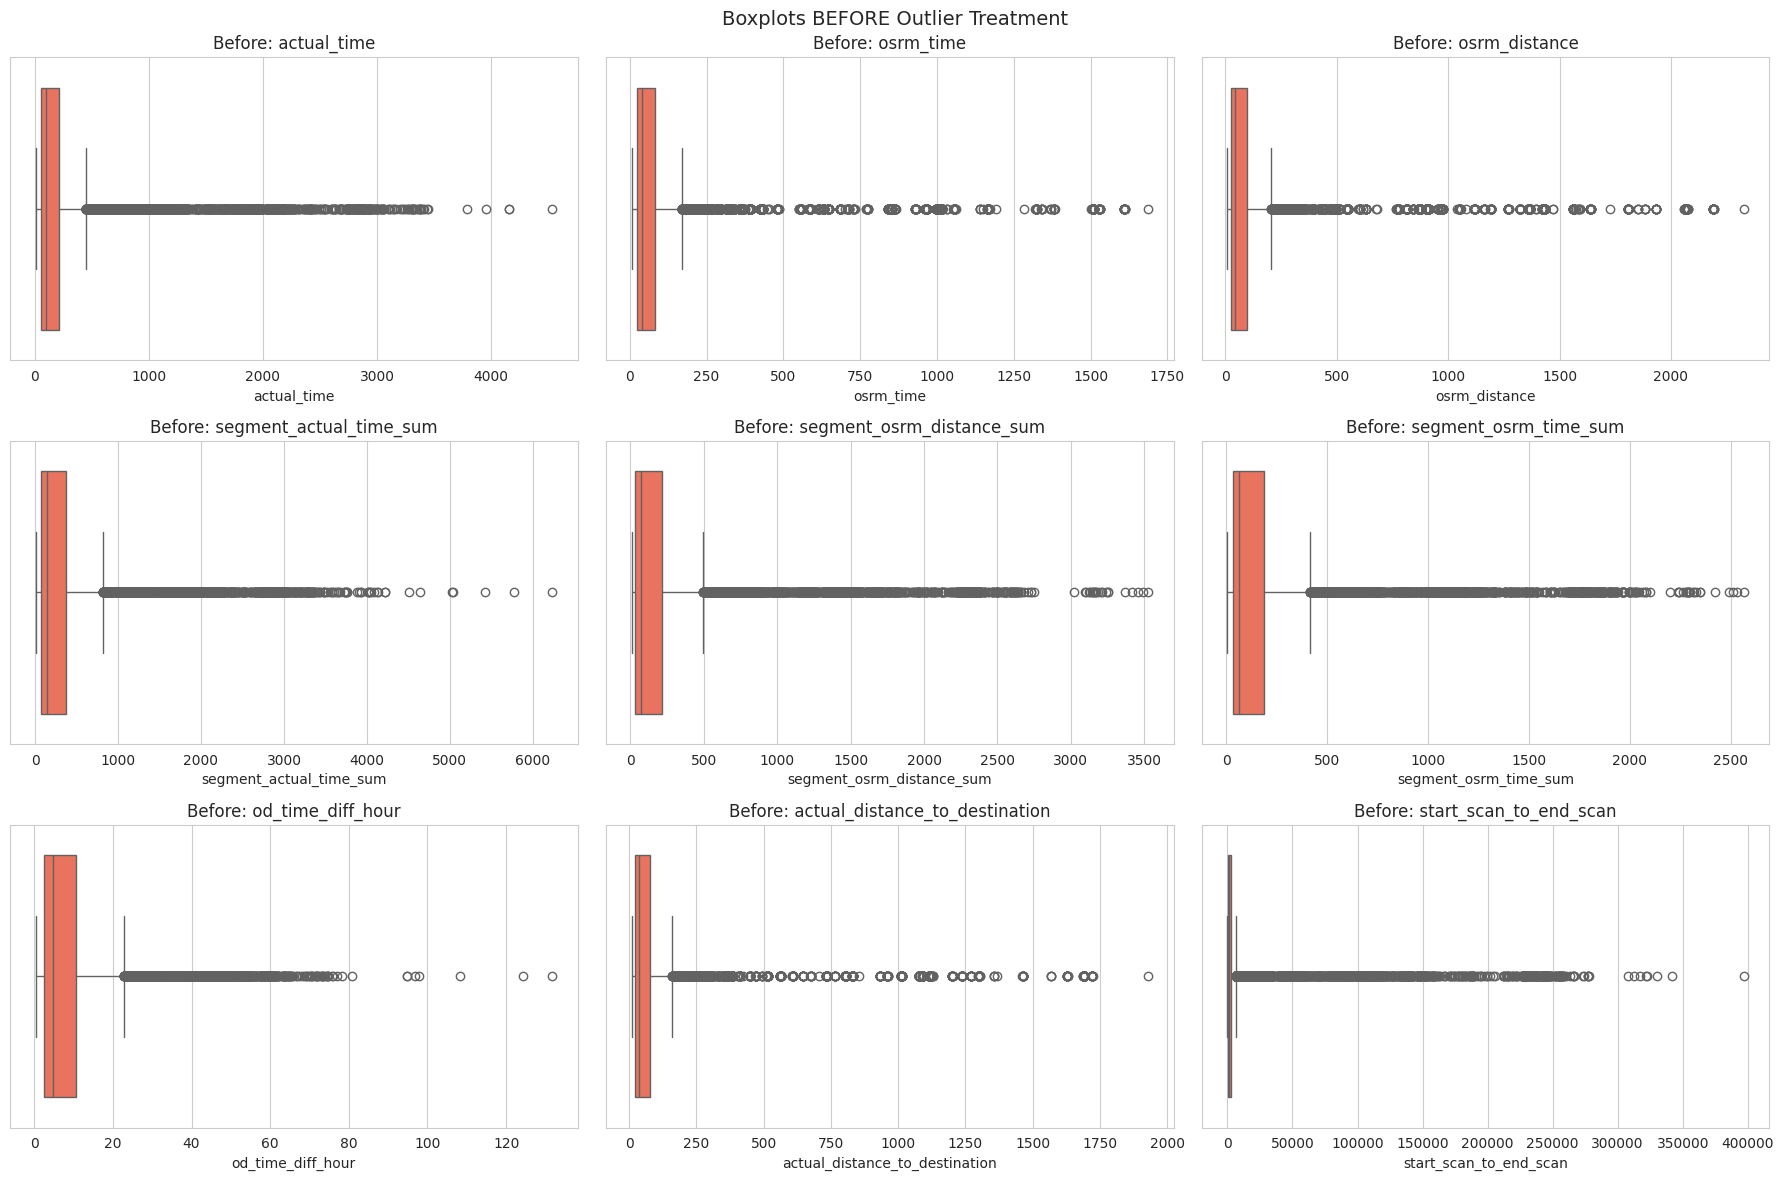

In [209]:
n = len(outlier_cols)
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(outlier_cols):
    sns.boxplot(x=trip[col], ax=axes[i], color="tomato")
    axes[i].set_title(f"Before: {col}")
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Boxplots BEFORE Outlier Treatment", fontsize=14)
plt.tight_layout()
plt.show()

### IQR-based capping

In [213]:
trip_outlier_treated = trip.copy()
outlier_report = {}

for col in outlier_cols:
    Q1 = trip_outlier_treated[col].quantile(0.25)
    Q3 = trip_outlier_treated[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((trip_outlier_treated[col] < lower) | (trip_outlier_treated[col] > upper)).sum()
    outlier_report[col] = {
        "outliers_found": n_outliers,
        "lower_cap": round(lower, 2),
        "upper_cap": round(upper, 2),
    }
    trip_outlier_treated[col] = trip_outlier_treated[col].clip(lower, upper)

print("\nOutlier Treatment Report (IQR Capping):")
print(f"{'Column':<35} {'Outliers':>10} {'Lower Cap':>12} {'Upper Cap':>12}")
print("-" * 72)
for col, info in outlier_report.items():
    print(
        f"{col:<35} {info['outliers_found']:>10} {info['lower_cap']:>12} {info['upper_cap']:>12}"
    )

print(f"\nRows BEFORE treatment: {len(trip)}")
print(f"Rows AFTER treatment : {len(trip_outlier_treated)}")


Outlier Treatment Report (IQR Capping):
Column                                Outliers    Lower Cap    Upper Cap
------------------------------------------------------------------------
actual_time                               1836       -179.5        448.5
osrm_time                                 1842        -63.0        169.0
osrm_distance                             1943       -80.66       206.16
segment_actual_time_sum                   1643       -385.5        818.5
segment_osrm_distance_sum                 1548      -246.57       498.02
segment_osrm_time_sum                     1492       -200.0        416.0
od_time_diff_hour                         1266        -9.71        22.84
actual_distance_to_destination            1998       -63.63       160.51
start_scan_to_end_scan                    2026      -3219.0       6453.0

Rows BEFORE treatment: 14817
Rows AFTER treatment : 14817


### Boxplots after treatment

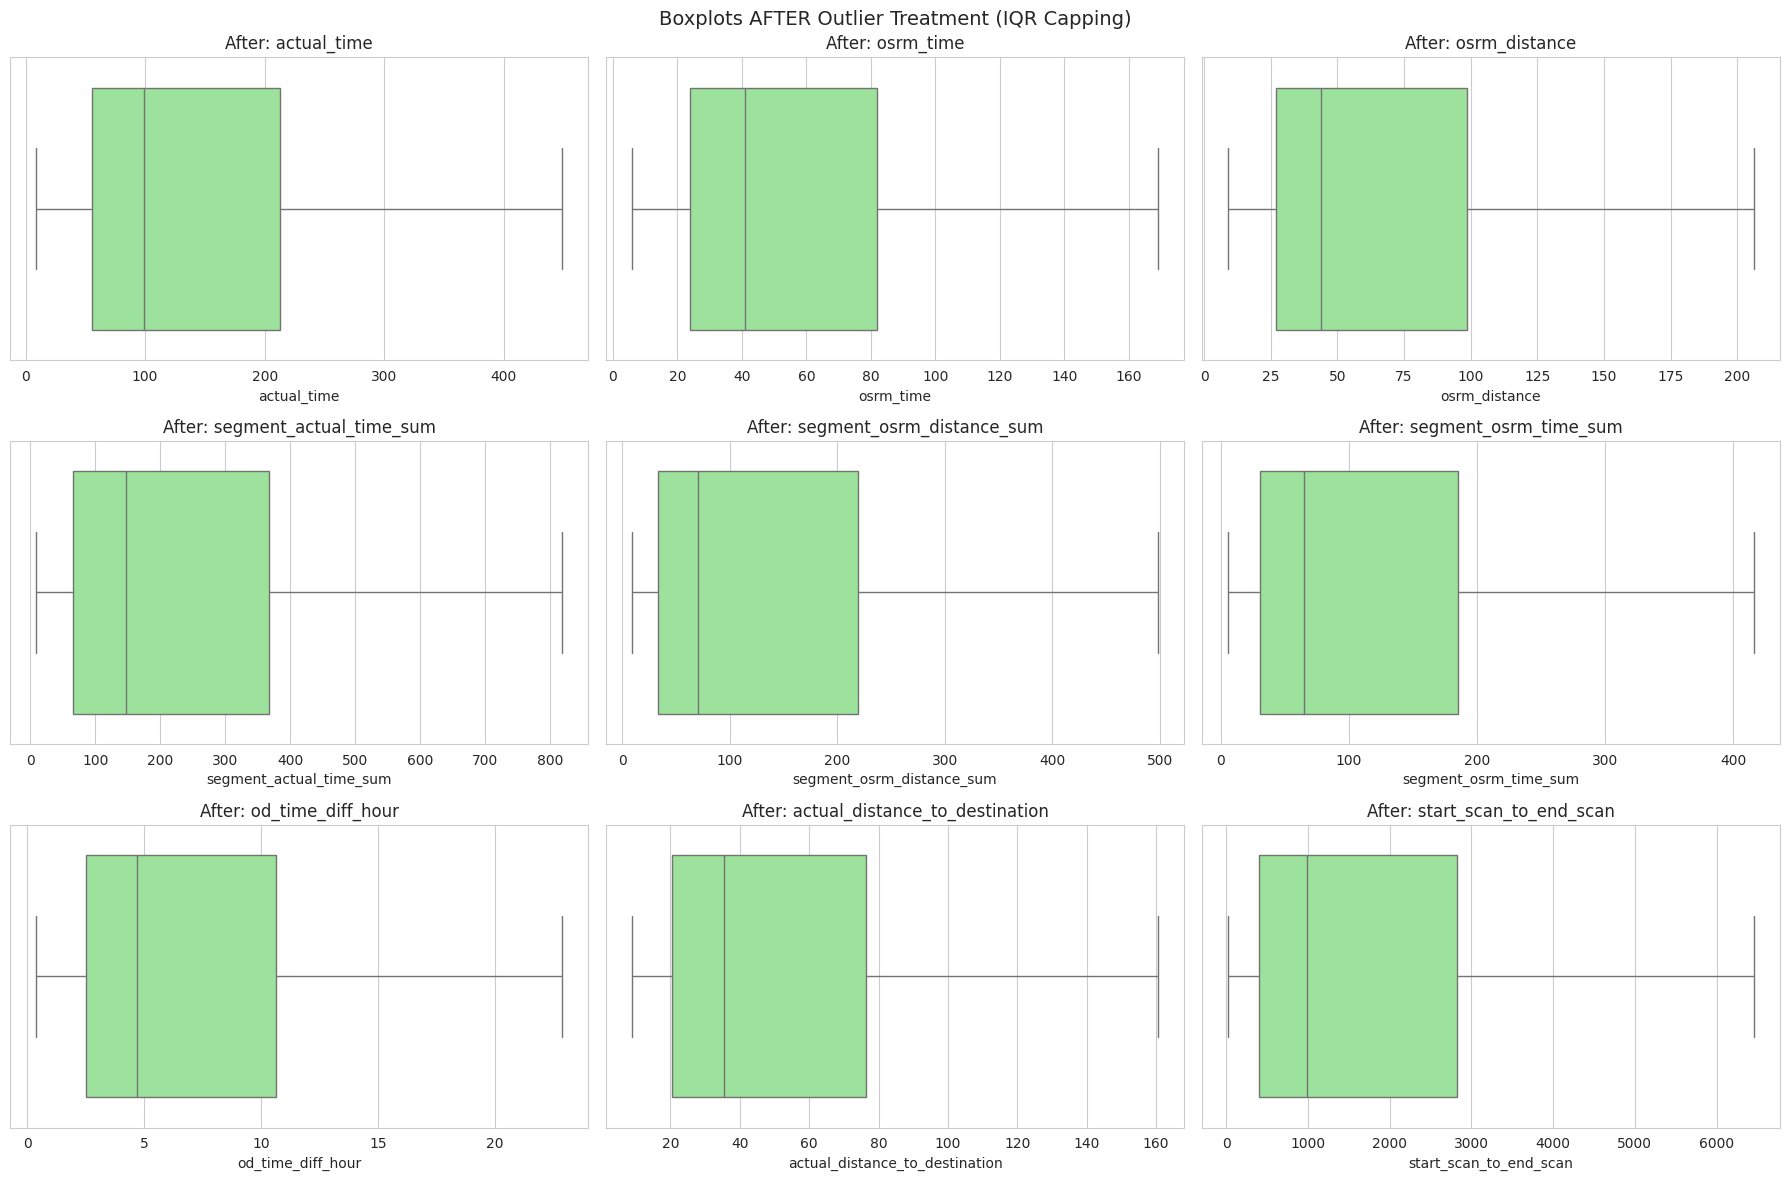

In [215]:
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(outlier_cols):
    sns.boxplot(x=trip_outlier_treated[col], ax=axes[i], color="lightgreen")
    axes[i].set_title(f"After: {col}")
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Boxplots AFTER Outlier Treatment (IQR Capping)", fontsize=14)
plt.tight_layout()
plt.show()

## One Hot Encoding

In [234]:
cat_check_cols = [
    "route_type",
    "source_state",
    "destination_state",
    "source_city",
    "destination_city",
    "source_name",
    "destination_name",
    "source_center",
    "destination_center",
]
for col in cat_check_cols:
    if col in trip_outlier_treated.columns:
        print(f"  {col:<30}: {trip_outlier_treated[col].nunique()}")

# Only encode route_type, source_state, destination_state (low cardinality)
ohe_cols = ["route_type", "source_state", "destination_state"]
ohe_cols = [c for c in ohe_cols if c in trip_outlier_treated.columns]

trip_encoded = pd.get_dummies(
    trip_outlier_treated,
    columns=ohe_cols,
    drop_first=True
)

print(f"\nShape BEFORE encoding: {trip_outlier_treated.shape}")
print(f"Shape AFTER encoding : {trip_encoded.shape}")

  route_type                    : 2
  source_state                  : 30
  destination_state             : 33
  source_city                   : 680
  destination_city              : 776
  source_name                   : 865
  destination_name              : 948
  source_center                 : 868
  destination_center            : 956

Shape BEFORE encoding: (14817, 26)
Shape AFTER encoding : (14817, 85)


## Feature Scaling

In [235]:
exclude_from_scaling = [
    "trip_uuid",
    "trip_month",
    "trip_day",
    "trip_dayofweek",
    "is_weekend",
]

scale_cols = [
    c for c in trip_encoded.select_dtypes(include=[np.number]).columns
    if c not in exclude_from_scaling
]

scaler = StandardScaler()
trip_scaled = trip_encoded.copy()
trip_scaled[scale_cols] = scaler.fit_transform(trip_encoded[scale_cols])

print(trip_scaled[scale_cols[:6]].head())

   actual_time  osrm_time  osrm_distance  segment_actual_time_sum  \
0     2.072079   2.087636       2.069439                 2.149256   
1    -0.803696  -0.713368      -0.706789                -0.465311   
2     2.072079   2.087636       2.069439                 2.149256   
3    -0.717745  -0.928830      -0.839693                -0.781760   
4    -0.202039  -0.360794      -0.310906                 0.302658   

   segment_osrm_distance_sum  segment_osrm_time_sum  
0                   2.262408               2.256743  
1                  -0.404369              -0.475861  
2                   2.262408               2.256743  
3                  -0.818804              -0.857336  
4                  -0.000954              -0.086601  


## Hypothesis Testing

### Actual Time vs OSRM Time

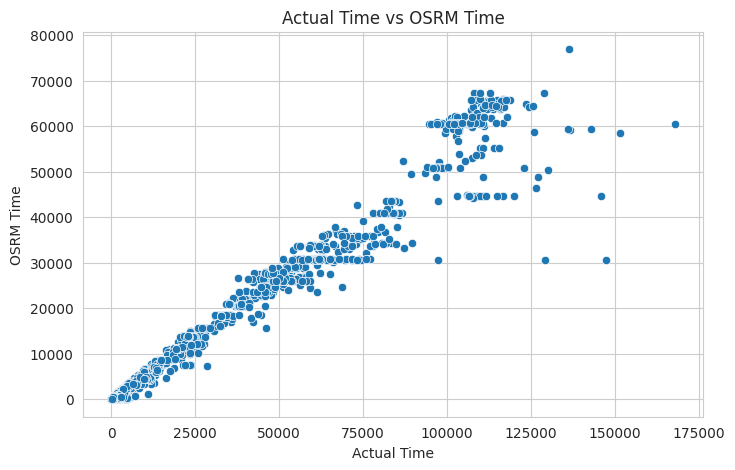

In [87]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=trip['actual_time'],
    y=trip['osrm_time']
)
plt.title('Actual Time vs OSRM Time')
plt.xlabel('Actual Time')
plt.ylabel('OSRM Time')
plt.show()

In [219]:
stat, p_value = ttest_rel(
    trip['actual_time'],
    trip['osrm_time']
)

print('T-statistic:', stat)
print('P-value:', p_value)

if p_value < 0.05:
    print('Decision: Reject Null Hypothesis — significant difference exists.')
else:
    print('Decision: Fail to Reject Null Hypothesis — no significant difference.')

T-statistic: 67.76836528976686
P-value: 0.0
Decision: Reject Null Hypothesis — significant difference exists.


### Actual Time vs Segment Actual Time

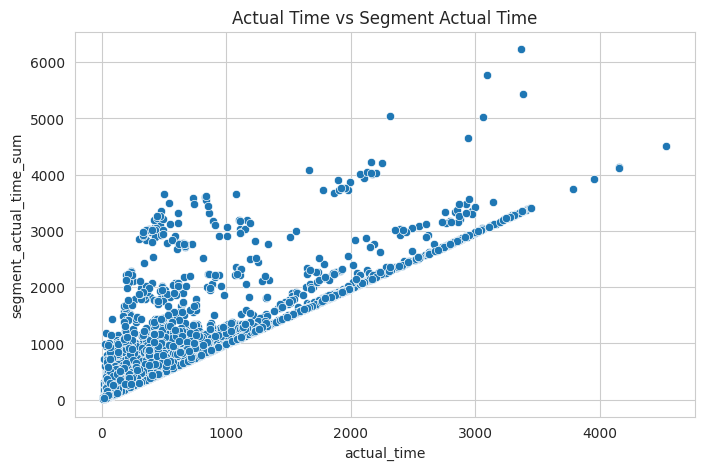

In [220]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=trip['actual_time'],
    y=trip['segment_actual_time_sum']
)
plt.title('Actual Time vs Segment Actual Time')
plt.show()

In [221]:
stat, p_value = ttest_rel(
    trip['actual_time'],
    trip['segment_actual_time_sum']
)

print('P-value:', p_value)

if p_value < 0.05:
    print('Decision: Reject Null Hypothesis — significant difference exists.')
else:
    print('Decision: Fail to Reject Null Hypothesis — no significant difference.')

P-value: 0.0
Decision: Reject Null Hypothesis — significant difference exists.


### OSRM Distance vs Segment OSRM Distance

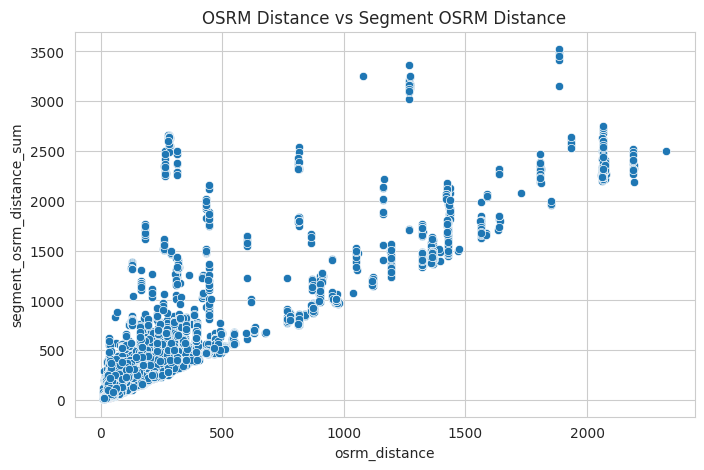

In [222]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=trip['osrm_distance'],
    y=trip['segment_osrm_distance_sum']
)
plt.title('OSRM Distance vs Segment OSRM Distance')
plt.show()

In [223]:
stat, p_value = ttest_rel(
    trip['osrm_distance'],
    trip['segment_osrm_distance_sum']
)

print('P-value:', p_value)

if p_value < 0.05:
    print('Decision: Reject Null Hypothesis — significant difference exists.')
else:
    print('Decision: Fail to Reject Null Hypothesis — no significant difference.')

P-value: 0.0
Decision: Reject Null Hypothesis — significant difference exists.


### OSRM Time vs Segment OSRM Time

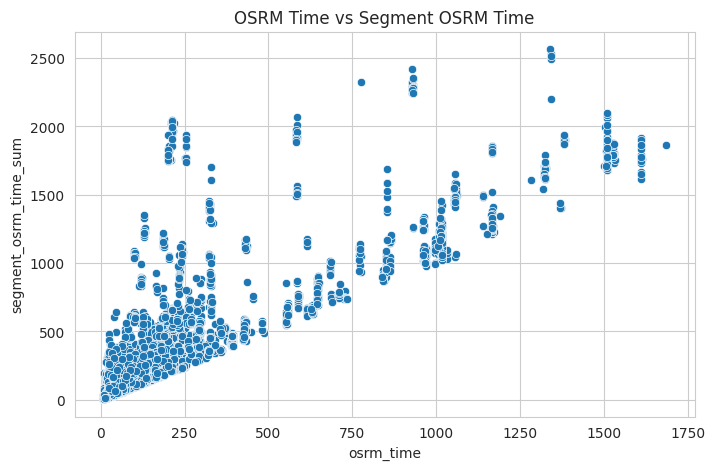

In [224]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=trip['osrm_time'],
    y=trip['segment_osrm_time_sum']
)
plt.title('OSRM Time vs Segment OSRM Time')
plt.show()

In [225]:
stat, p_value = ttest_rel(
    trip['osrm_time'],
    trip['segment_osrm_time_sum']
)

print('P-value:', p_value)

if p_value < 0.05:
    print('Decision: Reject Null Hypothesis — significant difference exists.')
else:
    print('Decision: Fail to Reject Null Hypothesis — no significant difference.')

P-value: 0.0
Decision: Reject Null Hypothesis — significant difference exists.


## Business Insights

### Top States by Volume


Top 10 Source States by Segment Count:
source_state
Maharashtra       3565
Karnataka         3453
Tamil Nadu        2130
Haryana           2056
Uttar Pradesh     1832
Telangana         1484
Gujarat           1401
West Bengal       1368
Andhra Pradesh    1310
Rajasthan         1176
Name: trip_uuid, dtype: int64


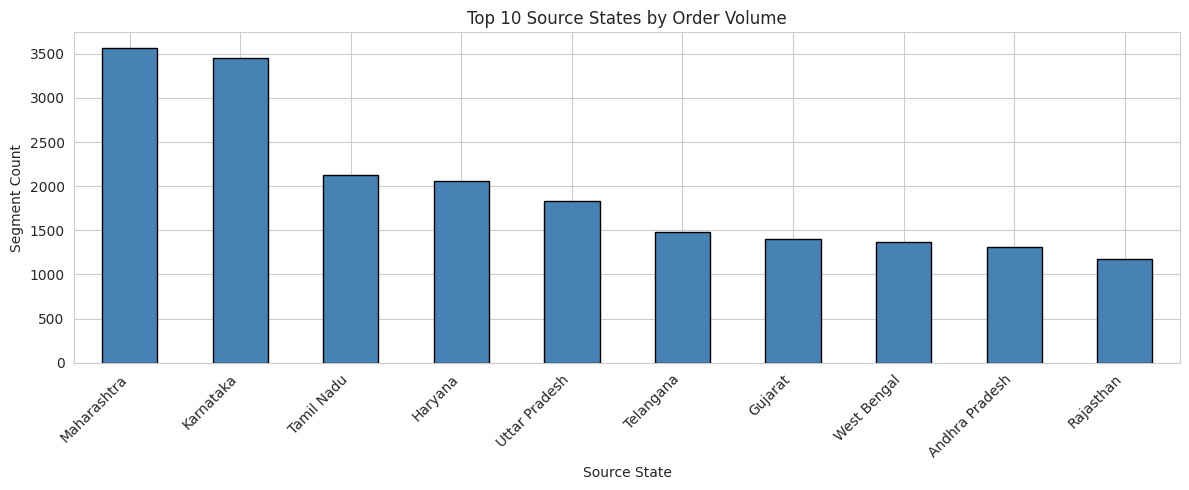

In [226]:
state_orders = (
    segment.groupby("source_state")["trip_uuid"]
    .count()
    .sort_values(ascending=False)
)

print("\nTop 10 Source States by Segment Count:")
print(state_orders.head(10))

plt.figure(figsize=(12, 5))
state_orders.head(10).plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Top 10 Source States by Order Volume")
plt.ylabel("Segment Count")
plt.xlabel("Source State")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Top Destination States


Top 10 Destination States:
destination_state
Karnataka         3505
Maharashtra       3473
Tamil Nadu        2111
Haryana           2019
Uttar Pradesh     1848
Telangana         1542
Gujarat           1401
West Bengal       1399
Andhra Pradesh    1315
Rajasthan         1210
Name: trip_uuid, dtype: int64


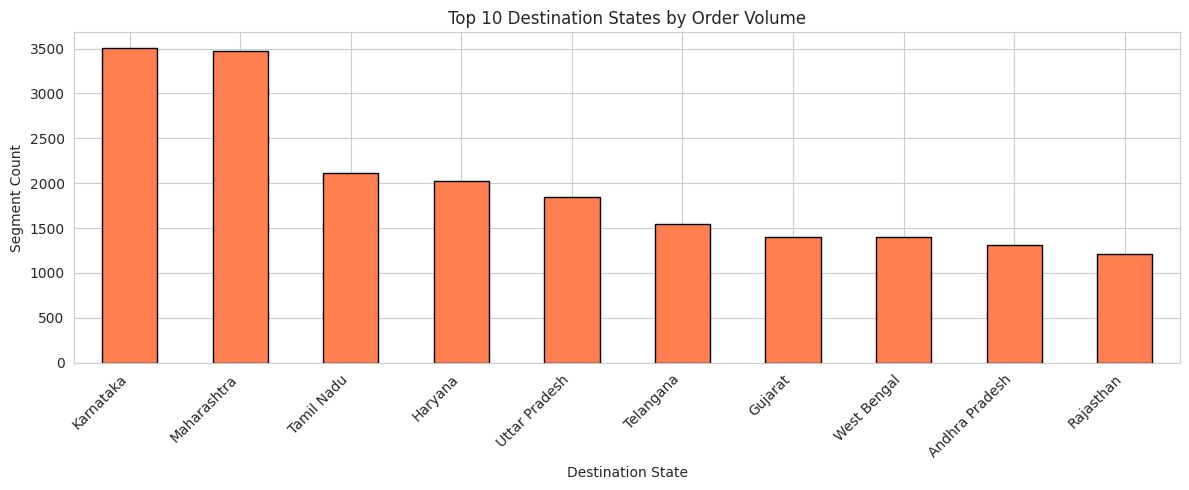

In [227]:
dest_state_orders = (
    segment.groupby("destination_state")["trip_uuid"]
    .count()
    .sort_values(ascending=False)
)

print("\nTop 10 Destination States:")
print(dest_state_orders.head(10))

plt.figure(figsize=(12, 5))
dest_state_orders.head(10).plot(kind="bar", color="coral", edgecolor="black")
plt.title("Top 10 Destination States by Order Volume")
plt.ylabel("Segment Count")
plt.xlabel("Destination State")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Corridor Analysis (City-level)


Top 10 Busiest Corridors:
                        trip_count  avg_osrm_distance  avg_actual_time  avg_osrm_time
city_corridor                                                                        
Bengaluru -> Bengaluru         565          36.769337        79.277876      39.438938
Bangalore -> Bengaluru         492          36.362374        77.674797      40.132114
Bhiwandi -> Mumbai             407          30.794135        80.120393      25.540541
Bengaluru -> Bangalore         356          36.695964        91.264045      44.794944
Hyderabad -> Hyderabad         316          32.398277       102.392405      26.585443
Mumbai -> Mumbai               286          17.227352        54.451049      14.370629
Mumbai -> Bhiwandi             282          28.976436        93.890071      24.709220
Delhi -> Gurgaon               248          48.385440       146.020161      46.306452
Chennai -> Chennai             246          23.817590        54.894309      20.756098
Gurgaon -> Delhi           

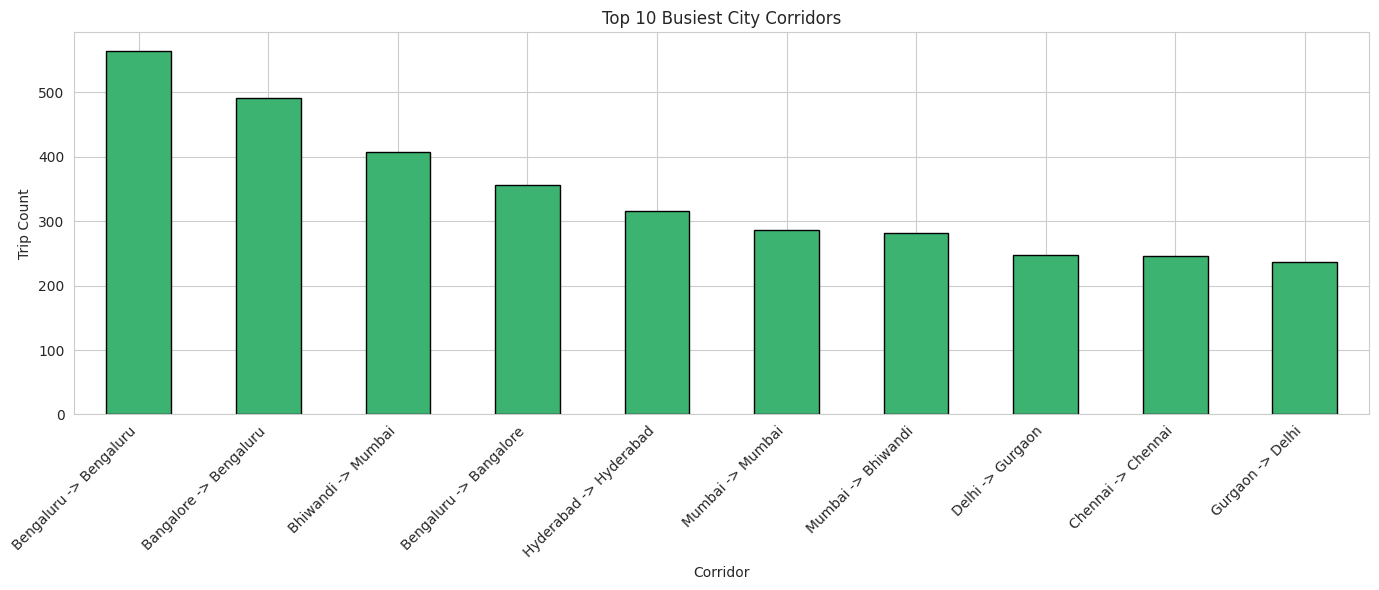

In [228]:
segment["city_corridor"] = (
    segment["source_city"] + " -> " + segment["destination_city"]
)

corridor_analysis = (
    segment.groupby("city_corridor")
    .agg(
        trip_count=("trip_uuid", "count"),
        avg_osrm_distance=("osrm_distance", "mean"),
        avg_actual_time=("actual_time", "mean"),
        avg_osrm_time=("osrm_time", "mean"),
    )
    .sort_values(by="trip_count", ascending=False)
)

print("\nTop 10 Busiest Corridors:")
print(corridor_analysis.head(10).to_string())

plt.figure(figsize=(14, 6))
corridor_analysis["trip_count"].head(10).plot(kind="bar", color="mediumseagreen", edgecolor="black")
plt.title("Top 10 Busiest City Corridors")
plt.ylabel("Trip Count")
plt.xlabel("Corridor")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Efficiency Gap: Actual vs OSRM Time per Corridor

In [229]:
corridor_analysis["time_gap_pct"] = (
    (corridor_analysis["avg_actual_time"] - corridor_analysis["avg_osrm_time"])
    / corridor_analysis["avg_osrm_time"]
) * 100

print("\nTop 10 Corridors with Highest Actual vs OSRM Time Gap (%):")
print(
    corridor_analysis[["trip_count", "avg_osrm_distance", "avg_actual_time",
                        "avg_osrm_time", "time_gap_pct"]]
    .sort_values("time_gap_pct", ascending=False)
    .head(10)
    .to_string()
)


Top 10 Corridors with Highest Actual vs OSRM Time Gap (%):
                                       trip_count  avg_osrm_distance  avg_actual_time  avg_osrm_time  time_gap_pct
city_corridor                                                                                                     
Gonda -> Tulsipur                               1          70.694400      2536.000000      50.000000   4972.000000
Kanchipuram -> MAA                              1          44.972600      1649.000000      34.000000   4750.000000
Mariani -> Jorhat                               3          20.000000       487.333333      15.666667   3010.638298
Phulpur -> Allahabad                           13          48.972177      1050.692308      36.230769   2800.000000
Jabalpur -> Jabalpur (Madhya Pradesh)           4          10.846075       228.250000       8.000000   2753.125000
Malvan -> Sawantwadi                           10          47.352840      1280.500000      45.500000   2714.285714
Varanasi -> MughalSa

### Route Type Performance


Route Type Performance:
            count  avg_actual_time  avg_osrm_time  avg_distance
route_type                                                     
Carting      8908        95.024360      35.369443     29.395363
FTL          5909       255.965815     103.198680     99.073263


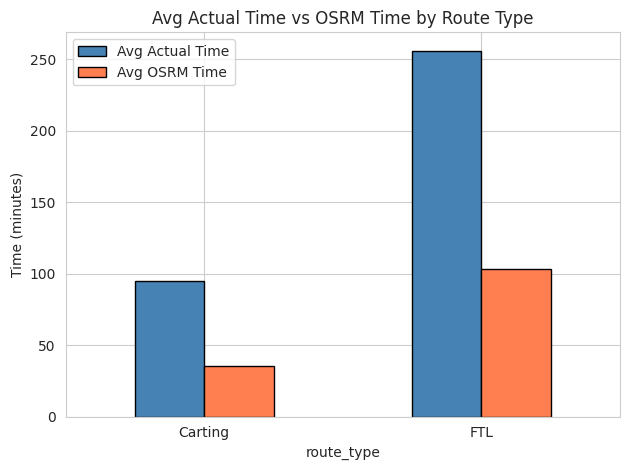

In [230]:
route_perf = trip_outlier_treated.groupby("route_type").agg(
    count=("trip_uuid", "count"),
    avg_actual_time=("actual_time", "mean"),
    avg_osrm_time=("osrm_time", "mean"),
    avg_distance=("actual_distance_to_destination", "mean"),
)
print("\nRoute Type Performance:")
print(route_perf)

route_perf[["avg_actual_time", "avg_osrm_time"]].plot(
    kind="bar", color=["steelblue", "coral"], edgecolor="black"
)
plt.title("Avg Actual Time vs OSRM Time by Route Type")
plt.ylabel("Time (minutes)")
plt.xticks(rotation=0)
plt.legend(["Avg Actual Time", "Avg OSRM Time"])
plt.tight_layout()
plt.show()

### Temporal Trends

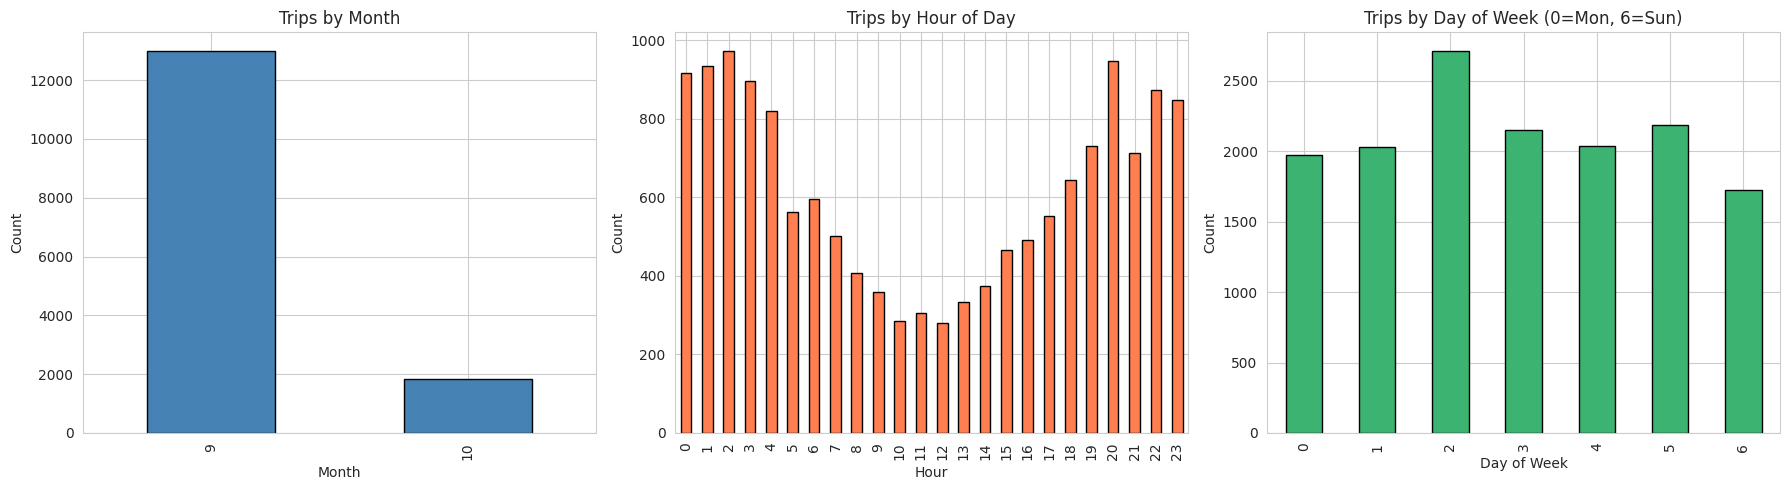

In [231]:
monthly = trip_outlier_treated.groupby("trip_month").size()
hourly  = trip_outlier_treated.groupby("trip_hour").size()
daily   = trip_outlier_treated.groupby("trip_dayofweek").size()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

monthly.plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Trips by Month")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("Month")

hourly.plot(kind="bar", ax=axes[1], color="coral", edgecolor="black")
axes[1].set_title("Trips by Hour of Day")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("Hour")

daily.plot(
    kind="bar", ax=axes[2], color="mediumseagreen", edgecolor="black"
)
axes[2].set_title("Trips by Day of Week (0=Mon, 6=Sun)")
axes[2].set_ylabel("Count")
axes[2].set_xlabel("Day of Week")

plt.tight_layout()
plt.show()

### Weekend vs Weekday volume


Weekday vs Weekend Trip Count:
Weekday    10903
Weekend     3914
dtype: int64


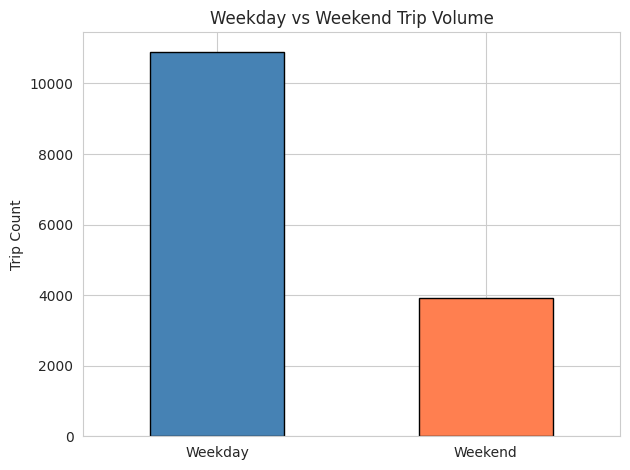

In [232]:
weekend_vol = trip_outlier_treated.groupby("is_weekend").size()
weekend_vol.index = ["Weekday", "Weekend"]
print("\nWeekday vs Weekend Trip Count:")
print(weekend_vol)

weekend_vol.plot(kind="bar", color=["steelblue", "coral"], edgecolor="black")
plt.title("Weekday vs Weekend Trip Volume")
plt.ylabel("Trip Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Key Findings

1. OSRM consistently underestimates actual delivery time across all
   4 hypothesis tests (all p-values < 0.05, H0 rejected). Actual time is approximately 1.7-2.3x the OSRM estimated time.

2. Actual time vs segment_actual_time_sum differ significantly,
   indicating scan capture gaps or hub dwell time not being
   recorded at the segment level.

3. OSRM distance vs segment_osrm_distance_sum differ significantly,
   suggesting route re-planning occurs during actual execution.

4. Maharashtra, Karnataka, Tamil Nadu, and Haryana are the top
   source states — contributing ~35% of all segments combined.

5. Bengaluru -> Bengaluru and Bangalore -> Bengaluru are the busiest
   corridors (intra-city), indicating high last-mile volume in Bengaluru.

6. Delhi -> Gurgaon and Gurgaon -> Delhi corridors show the highest
   actual time despite relatively short distances (~157-218 km),
   indicating severe congestion or hub delay on NH-48.

7. FTL dominates volume (99,660 rows) over Carting (45,207 rows),
   suggesting long-haul trips are more frequent than short-haul.

## Recommendations

1. Improve ETA Prediction
   - OSRM underestimates delivery time. Train an ML regression model
     using osrm_time, corridor, trip_hour, is_weekend, and route_type
     to predict an actual_time multiplier (factor column ~ 1.74 median).

2. Optimize Bengaluru Intra_City Operations
   - Bengaluru -> Bengaluru (565 trips) is the busiest single corridor.
     Deploy dedicated Carting fleet for intra-city deliveries to
     reduce congestion dependency.

3. Address delhi-Gurgaon Bottleneck
   - Delhi -> Gurgaon shows avg actual time of ~425 min for 157 km.
     Investigate NH-48 congestion windows and schedule dispatches
     during off-peak hours (late night / early morning).

4. Expand Hub capacity in top states
   - Maharashtra and Karnataka generate the highest order volumes.
     Prioritize new fulfillment center locations in Pune and Mysuru
     to reduce intra-state delivery distances.

5. Switch short haul FTL to carting
   - Many FTL trips cover short distances. Evaluate FTL trips under
     100 km and convert to Carting to reduce per-unit delivery cost.

6. Segment level KPI monitoring
   - Monitor segment_actual_time vs segment_osrm_time at each hub
     to pinpoint exact bottleneck legs rather than only trip-level KPIs.

7. Weekend capacity planning
   - Analyze weekend trip volumes; if demand spikes occur, pre-position
     fleet and manpower on Friday evenings for Saturday coverage.

8. Data quality improvement
   - source_name and destination_name have ~0.2% missing values.
     Implement mandatory hub name capture at scan points to avoid
     downstream feature engineering failures.